TP2 - Jann Luna Pedro - Matplotlib - 20/11/2025

L'objectif du deuxième TP est d'utiliser certaines fonctionnalités de visualisation de Matplotlib et quelques exercices de logique supplémentaires .

In [19]:
import numpy
import matplotlib.pyplot as plt

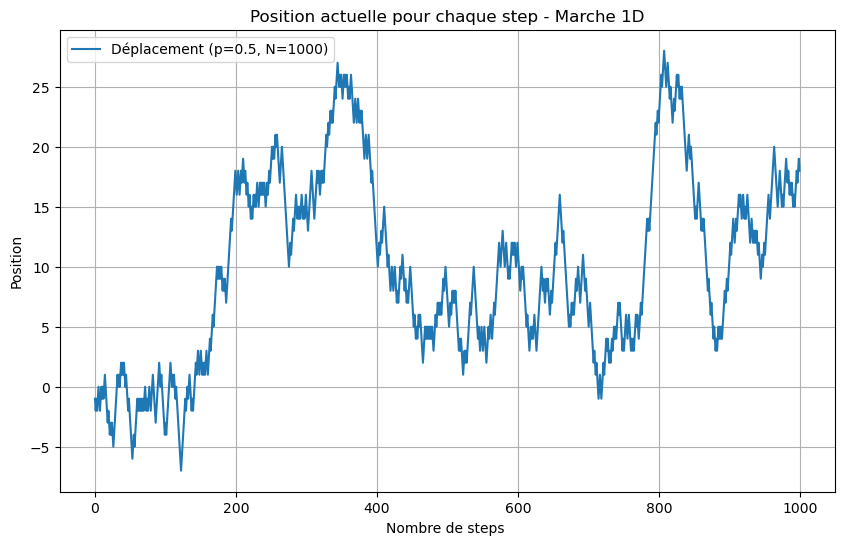

In [20]:
#1 Nous allons démontrer le déplacement en fonction du nombre de steps pour une marche avec p et N.

#Je vais utiliser les données générées dans tp1 pour exploiter ce qui a
#été généré. J'ai joint les fichiers .npy avec le fichier principal.
#j'ai également ajouté les graphiques générés au fichier


#data
steps = numpy.load('resultats_steps_pedro.npy')
position = numpy.cumsum(steps)

#graphique
plt.figure(figsize=(10, 6))

#info sur data
p = 0.5
n = 1000
label_info = f"Déplacement (p={p}, N={n})"

plt.plot(position, label=label_info)
plt.title("Position actuelle pour chaque step - Marche 1D")
plt.xlabel("Nombre de steps ")
plt.ylabel("Position")
plt.grid(True)

#légende
plt.legend()
plt.show()

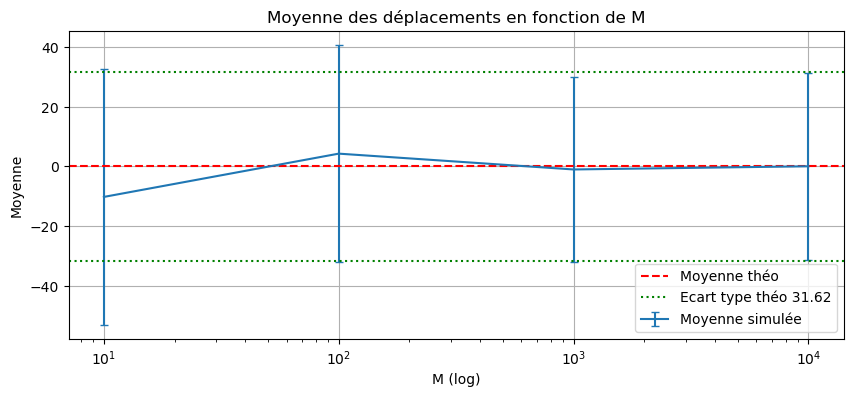

In [21]:
#j'ai déjà calculé l'écart type et la moyenne précédemment pour
# la comparaison, mais ils ne sont pas inclus dans ce tableau.
# Alors, je vais recalculer.

#data
data = numpy.load('resultats_marche_pedro.npy')
moyennes = data[0]
ecarts_types = data[1]

M = [10, 100, 1000, 10000]

#graphique
plt.figure(figsize=(10, 4))
plt.errorbar(M, moyennes, yerr=ecarts_types, linestyle='-', capsize=3, label='Moyenne simulée')

#erreurs
moyenne_t = n*(2*p - 1) 
ecart_type_t = numpy.sqrt(n * 4 * p * (1-p))

#moyenne
plt.axhline(y=moyenne_t, color='red', linestyle='--', label='Moyenne théo')

#meme chose aussi pour l'ecart type
plt.axhline(y=ecart_type_t, color='green', linestyle=':', label=f'Ecart type théo {ecart_type_t:.2f}')
plt.axhline(y=-ecart_type_t, color='green', linestyle=':')

#l'axe X en log
plt.xscale('log')
plt.title("Moyenne des déplacements en fonction de M")
plt.xlabel("M (log)")
plt.ylabel("Moyenne")
plt.legend()
plt.grid(True)
plt.show()

Il est ainsi plus facile de voir que les valeurs convergent vers les valeurs théoriques lorsque nous augmentons le M.

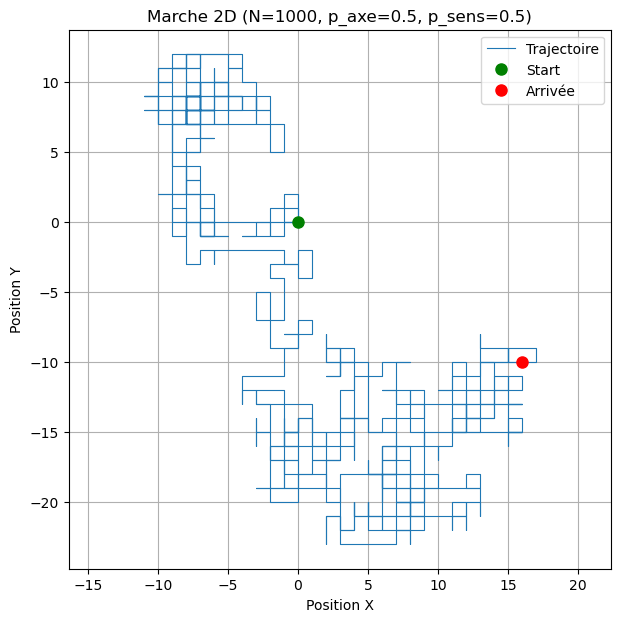

In [22]:
#2

# L'idée que j'ai eue pour la mise en œuvre était celle de deux probabilités : une pour
# décider de l'axe et une autre pour décider si cela va vers l'avant ou vers l'arrière.

numpy.random.seed(10) #pour être le même simulation

def marche_2d(N, p_axe, p_sens):
    
    #choix du sens 
    
    valeur_step = numpy.where(numpy.random.rand(N) < p_sens, 1, -1)
    
    #tirage  pour choisir l'axe
    tirage_axe = numpy.random.rand(N)
    
    
    #si le tirage est inférieur à p_axe, le step en x.
    #si le  est supérieur ou égal à p_axe, le step est en y.

    d_x = numpy.where(tirage_axe < p_axe, valeur_step, 0)
    d_y = numpy.where(tirage_axe >= p_axe, valeur_step, 0)
    
    # déplacement totale
    x = numpy.concatenate(([0], numpy.cumsum(d_x)))
    y = numpy.concatenate(([0], numpy.cumsum(d_y)))
    
    return x, y

n = 1000
prob_axe = 0.5   
prob_sens = 0.5  

x, y = marche_2d(n, prob_axe, prob_sens)

#graphique

plt.figure(figsize=(7, 7))
plt.plot(x, y, linewidth=0.8, label='Trajectoire')

# départ et arrivée
plt.plot(x[0], y[0], 'go', markersize=8, label='Start')
plt.plot(x[-1], y[-1], 'ro', markersize=8, label='Arrivée')

plt.title(f"Marche 2D (N={n}, p_axe={prob_axe}, p_sens={prob_sens})")
plt.xlabel("Position X")
plt.ylabel("Position Y")
plt.legend()
plt.grid(True)
plt.axis('equal') 
plt.show()

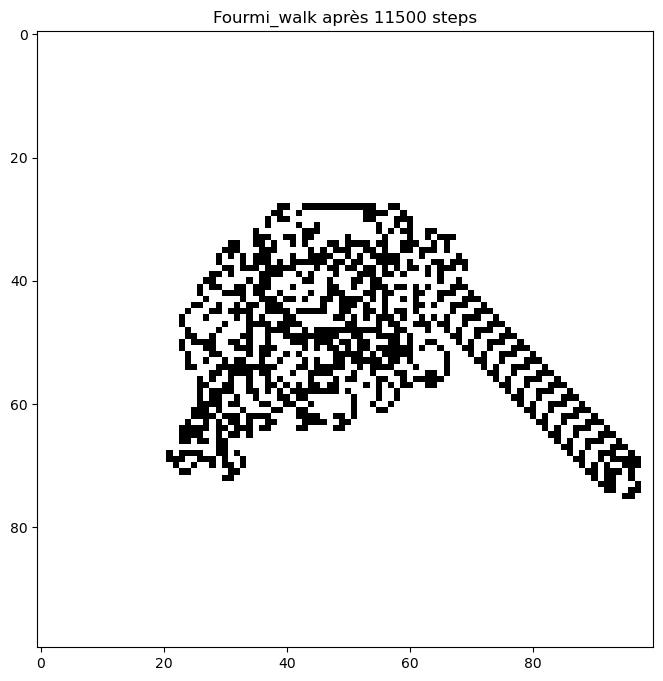

In [23]:
#3

def fourmi_walk(N_steps):
    
    # création de la grille (0 = Blanc, 1 = Noir)
    
    sz = 100
    grid = numpy.zeros((sz, sz))
    
    #position initiale 
    x = sz // 2
    y = sz // 2
    
    #directions
    
    directions = [(-1, 0), (0, 1), (1, 0), (0, -1)]
    i_direction = 0  

    #loop déplacement:
    for i in range(N_steps):
        
        # vérification des bords 
        if x < 0 or x >= sz or y < 0 or y >= sz:
            break
        
        # récuperer couleur actuelle
        couleur_act = grid[x, y]
        
        if couleur_act == 0: #blanche

            i_direction = (i_direction - 1) % 4
            grid[x, y] = 1 #inverse
            
        else: #noire
            
            i_direction = (i_direction + 1) % 4
            grid[x, y] = 0 #inverse
            
        # avancer
        d_x, d_y = directions[i_direction]
        x = x + d_x
        y = y + d_y
        
    return grid


#11500 steps (+ de 10000)
n = 11500
resultat = fourmi_walk(n) #test

#graphique 
plt.figure(figsize=(8, 8))
plt.imshow(resultat, cmap='binary')
plt.title(f"Fourmi_walk après {n} steps") 
plt.show()

Au début, la fourmi se déplace de façon chaotique, puis elle finit par construire une autoroute répétitive vers l'infini. Cela montre comment des règles très  peuvent créer de l'ordre à après le désordre.